# DS-A5 — Rolling-Origin Forecasting of MetroPT-3 TP2 Pressure

**Research notebook · protocol v1.0 · retrospective analysis**

**Research question and approach.** This retrospective study evaluates whether MetroPT-3 compressor `TP2` pressure can be forecast 600 elapsed seconds ahead. It applies a frozen chronological protocol to five final windows and compares persistence, seasonal-naive, and Ridge using saved predictions.

**Main measured findings.** Seasonal-naive has lower paired MAE and RMSE than persistence on 77,165 shared final forecasts, with lower availability. Ridge produced 64 scored final forecasts and only 27 targets shared by all three methods; this coverage is too sparse to establish broad comparative performance.

**Scope.** Source timestamps are timezone-naive and historical publication times are absent. The results describe an archive under the frozen retrospective availability assumption; they do not establish live data availability, operational acceptability, or causal drift.

The notebook's **standard review run** verifies hashes, reads the source observations and committed small summaries, and recreates compact tables and figures. It does not fit models. **Full reproduction** commands are documented separately and deliberately not run automatically.

<style>
@media print {
  pre, .highlight pre { white-space: pre-wrap !important; overflow-wrap: anywhere !important; word-break: break-word !important; max-width: 100% !important; }
  table { width: 100% !important; max-width: 100% !important; table-layout: auto !important; }
  th, td { overflow-wrap: break-word !important; word-break: normal !important; hyphens: none !important; }
  tr { break-inside: avoid; page-break-inside: avoid; }
  img { max-width: 100% !important; height: auto !important; }
}
</style>

## 1. Research question and motivation

**Question.** Under the frozen retrospective protocol, how accurately and how often can the next 10-minute `TP2` pressure value be forecast from information recorded no later than the issue time?

MetroPT-3 records pressure, temperature, current, and operating-state signals from an industrial air compressor. Pressure forecasting is relevant to monitoring, but this offline task does not establish an actionable warning system. Timestamp order and point-in-time feature rules matter because using measurements from after an issue time would leak future information.

MetroPT-3 was selected after local feasibility inspection. UR3 CobotOps had only about seven hours of data, 863 invalid timestamps, and a multi-hour gap; NOAA SanctSound remained **PARTIAL** because official ERDDAP observations were blocked by HTTP 403, not because the dataset was shown to be unavailable. See [`docs/dataset_selection.md`](../docs/dataset_selection.md), [`docs/alternative_dataset_audit.md`](../docs/alternative_dataset_audit.md), and [`docs/sources.md`](../docs/sources.md).

The current [official DS-A5 assignment catalog](https://tjluo-ucas.github.io/ds/en/assignments/) lists time order, rolling origin, leakage checks, drift, and failure cases as core evidence. Its minimum standard calls for an executable notebook or equivalent, PDF, reproduction commands, provenance/environment, actual outputs, a counterexample or applicability boundary, and an AI-use record. The [submission guide](https://tjluo-ucas.github.io/ds/en/submission-guide/) specifies code/README on GitHub, written materials in Drive, and a course-platform submission record. These live pages were rechecked 2026-11-22. The exact course-page release/deadline is not used here because the platform record is authoritative.

## 2. Dataset provenance and temporal audit

The official source is [UCI MetroPT-3](https://archive.ics.uci.edu/dataset/791/metropt3%2Bdataset), distributed as `MetroPT3(AirCompressor).csv` under CC BY 4.0. The original CSV is excluded from Git and must be obtained and placed at `data/raw/metropt3/MetroPT3(AirCompressor).csv`; its expected SHA-256 is checked below. The CSV contains an `Unnamed: 0` file-index field in addition to its timestamp and 15 sensor/state signals. The index field is not a sensor and is excluded from sensor counts and missingness. Time values are **naive**: neither the timezone nor device-clock accuracy is established. The September 2020 records are only a partial month. Missing sensor cells are counted separately from missing elapsed-time intervals; interruption causes are unknown.

The monthly summaries show a strongly uneven TP2 marginal distribution. In June, the 75th percentile is 7.348 bar while the median is −0.012 bar; 7.348 is not the monthly median. A marginal pressure quantile is distinct from issue-to-target pressure change and forecast error. Observed changes in TP2, motor-current, and operating-state composition do not identify sensor drift, equipment faults, or a cause of prediction error.

In [1]:
from pathlib import Path
import base64, hashlib, json, os, subprocess, sys, tempfile

# Resolve the repository from this notebook's location; allow execution from any cwd.
HERE = Path.cwd().resolve()
for candidate in (HERE, *HERE.parents):
    if (candidate / "TASK.md").exists() and (candidate / "docs/evaluation_protocol_v1.md").exists():
        ROOT = candidate
        break
else:
    raise RuntimeError("Cannot locate DS-A5 project root (expected TASK.md and docs/).")
os.environ.setdefault("MPLCONFIGDIR", str(Path(tempfile.gettempdir()) / "ds-a5-matplotlib"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()

def project_path(relative):
    path = ROOT / relative
    if not path.is_file():
        raise FileNotFoundError(f"Required project artifact is missing: {relative}")
    return path

def show_png_with_alt(png_bytes, alt_text):
    encoded = base64.b64encode(png_bytes).decode("ascii")
    display(Markdown(f"![{alt_text}](data:image/png;base64,{encoded})"))

print("Project root discovery: PASS (located from repository markers)")
print(f"Python: {sys.version.split()[0]} | pandas: {pd.__version__} | NumPy: {np.__version__} | matplotlib: {plt.matplotlib.__version__}")

Project root discovery: PASS (located from repository markers)
Python: 3.10.18 | pandas: 2.3.1 | NumPy: 2.2.6 | matplotlib: 3.10.5


In [2]:
freeze = json.loads(project_path("docs/evaluation_protocol_freeze_manifest.json").read_text())
expected = dict(freeze["document_sha256"])
expected[freeze["diagnostics"]["path"]] = freeze["diagnostics"]["sha256"]
expected.update(freeze["source_script_sha256"])
integrity = []
for rel, digest in expected.items():
    actual = sha256(project_path(rel))
    assert actual == digest, f"Frozen artifact hash mismatch: {rel}"
    integrity.append({"artifact": rel, "sha256": actual, "verified": True})
dataset_rel = freeze["dataset"]["file"]
dataset_hash = sha256(project_path(dataset_rel))
assert dataset_hash == freeze["dataset"]["sha256"]
analysis_manifest = json.loads(project_path("results/analysis/analysis_manifest.json").read_text())
assert analysis_manifest["protocol_commit"] == "ca83f0a295a68337aebc070cfd481645418cda13"
assert analysis_manifest["dataset_sha256"] == dataset_hash
for rel, digest in analysis_manifest["outputs"].items():
    assert sha256(project_path(rel)) == digest, f"Phase 3 artifact hash mismatch: {rel}"
for phase in ("development", "final"):
    metrics_rel = f"results/rolling/{phase}_metrics.json"
    metrics_hash = {
        "development": "1c97599d08311a2cadca555313ee1ab87d7c3648539e34f73235c316dafde641",
        "final": "6af02ab6d02e491b622f66d3b0b45b62a871a6c264f917c92d519ced2f9f4d11",
    }[phase]
    assert sha256(project_path(metrics_rel)) == metrics_hash, f"Phase 2B {phase} metrics hash mismatch"
    run_manifest = json.loads(project_path(f"results/rolling/{phase}_manifest.json").read_text())
    assert run_manifest["freeze_commit"] == "ca83f0a295a68337aebc070cfd481645418cda13"

ancestor = subprocess.run(["git", "merge-base", "--is-ancestor", "ca83f0a295a68337aebc070cfd481645418cda13", "HEAD"], cwd=ROOT, check=False)
assert ancestor.returncode == 0, "Frozen protocol commit is not an ancestor of HEAD."
verified_hashes = integrity + [{"artifact": dataset_rel, "sha256": dataset_hash, "verified": True}]
display(Markdown("**Verified SHA-256 records**\n\n" + "\n".join(f"- `{item['artifact']}` — `{item['sha256']}`" for item in verified_hashes)))
print("Frozen documents, source data, saved outputs, and Phase 5A diagnostic hashes verified.")

posthoc_manifest = json.loads(project_path("results/student_review_diagnostics/diagnostic_manifest.json").read_text())
assert posthoc_manifest["status"] == "PASS" and posthoc_manifest["source_hashes_before"] == posthoc_manifest["protected_hashes_after"]
revision_targets = {"notebooks/DS_A5_rolling_forecasting.ipynb", "submission/DS_A5_rolling_forecasting.pdf"}
for rel, digest in posthoc_manifest["source_hashes_before"].items():
    if rel not in revision_targets:
        assert sha256(project_path(rel)) == digest, f"Protected Phase 5A source changed: {rel}"
for rel, digest in posthoc_manifest["output_hashes"].items():
    assert sha256(project_path(rel)) == digest, f"Phase 5A output hash mismatch: {rel}"
for rel, digest in posthoc_manifest["diagnostic_code_sha256"].items():
    assert sha256(project_path(rel)) == digest, f"Phase 5A code hash mismatch: {rel}"
print(f"Phase 5A evidence verified; {len(posthoc_manifest['source_hashes_before'])-len(revision_targets)} protected hashes unchanged.")

**Verified SHA-256 records**

- `docs/evaluation_protocol_v1.md` — `3cce2f55892e8355c27e5fa1721d4d81a8f3dd70b883e00d45501bc94725d6b3`
- `docs/feature_availability.md` — `389354c89c5855573343c211873571eb7502e145d764eca5682caae178ca3b34`
- `docs/forecasting_task_definition.md` — `5c2d10ec670f0ebcd09166f75c9e8c8ba9cbf1e90451d9c00a4ff98696540d49`
- `results/audit/forecasting_task_diagnostics.json` — `bf6ae08b38233a50575cf502847d470edc6ca70bec39e8605ce8a338a9d83ef0`
- `scripts/diagnose_forecast_task.py` — `c4e9937f173c7a816cfbb32b52adefbb61fc7bc5c7b16468afc9915e2a2b9800`
- `scripts/temporal_rules.py` — `0a3d164e6274f85d4a840bc918f03326643a939534f6129f0b40614f036b68ec`
- `scripts/audit_alternatives.py` — `ccce8b1c818f2a2396fadad66dc6ad85c5805dac4e7cbbd12001e5ac9a406650`
- `scripts/audit_noaa.py` — `0d22bfd659a389e8731ca2ac7c3fed1d155adba130666f845a7d12da0e96c296`
- `data/raw/metropt3/MetroPT3(AirCompressor).csv` — `db30ccb4ea402e3c8bf2c99db06e288d4f2a772f6928f9dbe26a920d69793e24`

Frozen documents, source data, saved outputs, and Phase 5A diagnostic hashes verified.


Phase 5A evidence verified; 46 protected hashes unchanged.


In [3]:
# Read actual source observations; source timestamp strings are parsed but kept timezone-naive.
raw = pd.read_csv(project_path(dataset_rel), low_memory=False)
assert len(raw) == 1_516_948
assert raw["timestamp"].notna().all()
ts = pd.to_datetime(raw["timestamp"], errors="raise")
assert ts.dt.tz is None
delta = ts.diff().dt.total_seconds().dropna()
file_index_cols = [c for c in raw.columns if c.startswith("Unnamed:") or c.lower() in {"index", "row_index"}]
sensor_cols = [c for c in raw.columns if c != "timestamp" and c not in file_index_cols]
missing_cells = int(raw[sensor_cols].isna().sum().sum())
assert ts.is_monotonic_increasing
assert int(ts.duplicated().sum()) == 0
assert missing_cells == 0
overview = pd.DataFrame([
    ("Rows", f"{len(raw):,}"),
    ("Raw CSV fields", f"{len(raw.columns)} total: {len(file_index_cols)} file index ({', '.join(file_index_cols)}); timestamp; {len(sensor_cols)} sensor/state fields"),
    ("Sensor/state fields", ", ".join(sensor_cols)),
    ("Timestamp range (naive)", f"{ts.min()} to {ts.max()}"),
    ("Timezone", "Not encoded / unknown"),
    ("Timestamp ordering", "Monotone increasing; no duplicate timestamps"),
    ("Interval median / p05 / p95", f"{delta.median():.1f} / {delta.quantile(.05):.1f} / {delta.quantile(.95):.1f} seconds"),
    ("Intervals >60 seconds", f"{int((delta > 60).sum()):,} ({(delta > 60).mean():.6%})"),
    ("Missing sensor cells", f"{missing_cells:,} across {len(sensor_cols)} sensor columns"),
    ("Partial final month", "September 2020 ends at 2020-09-01 03:59:50"),
], columns=["Audit item", "Observed result"])
display(overview)
display(raw[["TP2", "TP3", "Motor_current", "Oil_temperature"]].describe(percentiles=[.05,.25,.5,.75,.95]).T.round(4))
print("Interpretation: absent elapsed-time intervals are not represented as missing CSV rows/cells; their causes are unknown.")

,Audit item,Observed result
0,Rows,"1,516,948"
1,Raw CSV fields,17 total: 1 file index (Unnamed: 0); timestamp...
2,Sensor/state fields,"TP2, TP3, H1, DV_pressure, Reservoirs, Oil_tem..."
3,Timestamp range (naive),2020-02-01 00:00:00 to 2020-09-01 03:59:50
4,Timezone,Not encoded / unknown
5,Timestamp ordering,Monotone increasing; no duplicate timestamps
6,Interval median / p05 / p95,10.0 / 9.0 / 10.0 seconds
7,Intervals >60 seconds,331 (0.021820%)
8,Missing sensor cells,0 across 15 sensor columns
9,Partial final month,September 2020 ends at 2020-09-01 03:59:50


,count,mean,std,min,5%,25%,50%,75%,95%,max
TP2,1516948.0,1.3678,3.2509,-0.032,-0.0160,-0.014,-0.012,-0.0100,9.5900,10.676
TP3,1516948.0,8.9846,0.6391,0.730,8.1380,8.492,8.960,9.4920,9.9800,10.302
Motor_current,1516948.0,2.0502,2.3021,0.020,0.0375,0.040,0.045,3.8075,5.9875,9.295
Oil_temperature,1516948.0,62.6442,6.5163,15.400,52.3250,57.775,62.700,67.2500,73.5250,89.050


Interpretation: absent elapsed-time intervals are not represented as missing CSV rows/cells; their causes are unknown.


## 3. Forecast definition and point-in-time availability

The issue time is a source event timestamp `t`. The nominal target is `t + 600 s`; the actual label is the earliest observed record in `[t+600 s, t+605 s]`. The selected record must be future-only. Issue and target TP2 must be finite, and the segment may contain no adjacent timestamp gap greater than 60 seconds. Historical features use the latest record at or before `t-lag`, with age no more than 5 seconds, finite values, and no prohibited gap through the issue row. No interpolation or future lookup is permitted.

| Quantity | Source time used | Availability rule at issue | What is established |
|---|---|---|---|
| TP2 target | Actual matched future row | Label must be observed; training label's actual timestamp `<= origin`; evaluation label `< window end` | Archive event time only; publication time unknown |
| Persistence | TP2 recorded at the observed issue timestamp `t` | Exact issue-row lookup (age 0); finite; valid history gap | Archive observation at issue time; publication time unverified |
| Seasonal-naive | Latest TP2 at/before `t + 600 s - 24 h` | Reference age `0–5 s`, finite and timestamp `<=t`; reference row only, no full-day continuity rule | Retrospective assumed available |
| Ridge `TP2_lag_10s` | Latest row `<=t-10 s` | Age `0–5 s`; finite; valid gap | Historical release time unverified |
| Ridge `TP2_lag_60s`, `TP3_lag_60s`, `Motor_current_lag_60s` | Latest row `<=t-60 s` | Same | Historical release time unverified |
| Ridge `TP2_lag_300s`, `TP3_lag_300s`, `Motor_current_lag_300s` | Latest row `<=t-300 s` | Same | Historical release time unverified |

For evaluated issues, the source contains TP2 at the issue timestamp, so persistence has zero lookup age. Seasonal-naive needs a past observation within five seconds of its one-day-back reference. Ridge requires all seven lag lookups to pass their age, finite-value, and continuity rules; the 300-second lag is the observed major bottleneck.

All availability claims are under the frozen **zero-additional-latency retrospective assumption**. The data do not document a historical release timestamp, so production availability cannot be verified. Labels are not presumed complete at the beginning of the target bin; the protocol uses retrospectively archived values and does not establish a real-time alerting latency.

## 4. Frozen evaluation protocol

The experimental rules were frozen before the final evaluation; this notebook reports and checks that evidence without changing it. Freeze commit: `ca83f0a295a68337aebc070cfd481645418cda13`; manifest: [`docs/evaluation_protocol_freeze_manifest.json`](../docs/evaluation_protocol_freeze_manifest.json).

- **Development origins:** D1 2020-03-01, D2 2020-04-01, D3 2020-05-01, D4 2020-06-01, D5 2020-07-01; each has a 14-day evaluation window.
- **Final origins:** F1 2020-08-01–06, F2 08-07–12, F3 08-13–18, F4 08-19–24, F5 08-25–30 (left-closed/right-open).
- Training expands through each origin; training issues `< origin`, and matched training labels must be `<= origin`. Evaluation issues are inside the window and matched labels must be `< end`.
- Ridge: seven fixed lags, `StandardScaler` refit on eligible training rows per origin, `Ridge(alpha=1.0, fit_intercept=True, solver="svd")`; no tuning.
- Baselines: persistence and 24-hour seasonal-naive, each unavailable when its frozen lookup rule fails.
- MAE and RMSE use only rows with both an eligible target pair and an available method prediction. Coverage is reported separately. Common-target metrics use identical origin/issue/target identities across all three methods.
- Mechanical assertions check future-only matching, boundaries, training-label availability, finite inputs, and saved metric consistency.

Ridge had no eligible training samples at D1, so no Ridge fit was produced for that origin. D2–D5 and all five final origins have fit status recorded in the saved results.

## 5. Reproducible implementation

Implementation is maintained once in [`src/temporal.py`](../src/temporal.py), [`src/rolling_evaluation.py`](../src/rolling_evaluation.py), and [`src/metrics.py`](../src/metrics.py). The notebook validates the frozen source hashes and consumes audited metric/analysis summaries; it does not maintain a duplicate forecasting pipeline. The clean-kernel standard run is independent of notebook variables and does not retrain the ten origins.

**Layer A — standard review:** run this notebook top-to-bottom from a clean kernel with the README command. It requires (1) the original MetroPT-3 CSV locally at `data/raw/metropt3/MetroPT3(AirCompressor).csv` (excluded from Git; expected SHA-256 is in `docs/artifact_registry.md`) and (2) the committed rolling metrics, audit summaries, Phase 3 summaries, manifest, and referenced figures. A Git clone alone does not include the source CSV. Layer A verifies hashes, audits source observations, rebuilds review tables/figures, and exercises protocol assertions; it does not read large prediction CSVs or retrain models.

**Layer B — full experimental reproduction (explicit, not automatically run here):** first obtain and hash-check the same excluded raw CSV, then follow the exact commands in [`README.md`](../README.md) to rerun the frozen development/final origins, `verify_rolling_outputs.py`, `audit_phase2b_outputs.py`, and `analyze_phase3.py`. The Phase 2B runner writes large prediction CSVs and overwrites the current top-level phase outputs; preserve local evidence before intentionally rerunning it. See [`docs/artifact_registry.md`](../docs/artifact_registry.md) for hashes and regeneration instructions.

Unavailable predictions remain null with explicit unavailable status/reason in source outputs. They are never converted to zero-error rows. The notebook's standard path uses already audited small summaries and does not need large prediction CSVs.

In [4]:
# Load verified small outputs and test frozen evaluation invariants.
dev = json.loads(project_path("results/rolling/development_metrics.json").read_text())
final = json.loads(project_path("results/rolling/final_metrics.json").read_text())
funnel = pd.read_csv(project_path("results/audit/phase2b_coverage_funnel.csv"))
origin_summary = pd.read_csv(project_path("results/analysis/origin_metric_coverage_summary.csv"))
assert [o["origin_id"] for o in final["origins"]] == ["F1","F2","F3","F4","F5"]
assert [o["origin_id"] for o in dev["origins"]] == ["D1","D2","D3","D4","D5"]
assert dev["origins"][0]["status"] == "FAILED_NO_TRAINING_ROWS"
assert dev["origins"][0]["training_sample_count"] == 0
assert final["pooled_method_specific"]["ridge"]["count"] == 64
assert final["pooled_common_targets"]["persistence"]["count"] == 27
print("Saved metrics contain five development and five final origins; D1 has no Ridge training rows.")

Saved metrics contain five development and five final origins; D1 has no Ridge training rows.


## 6. Rolling evaluation results

Candidate issue times, valid target pairs, available predictions, and scored forecasts have different denominators. A forecast is scored only when both a prediction and an eligible target pair are present. Method-specific errors describe different selected populations; paired comparisons require shared issue/target identities and explicit counts.

In [5]:
# Development status is shown separately: an origin record is not proof of a successful Ridge fit.
dev_view = pd.DataFrame([{
    "Origin":o["origin_id"],"Fit":"No fit" if o["status"] == "FAILED_NO_TRAINING_ROWS" else "Completed",
    "Issues":o["candidate_issue_count"],"Valid targets":o["valid_target_pair_count"],
    "Train n":o["training_sample_count"],"Pred n":o["method_metrics"]["ridge"]["prediction_count"],
    "Scored n":o["method_metrics"]["ridge"]["count"]
} for o in dev["origins"]])
display(dev_view.style.hide(axis="index"))
assert dev["origins"][0]["status"] == "FAILED_NO_TRAINING_ROWS" and dev_view.loc[0,"Train n"] == 0
print("D1 remains an explicit failed Ridge origin; D2–D5 completed under the frozen rules.")

Origin,Fit,Issues,Valid targets,Train n,Pred n,Scored n
D1,No fit,103456,101251,0,0,0
D2,Completed,94505,92351,158,303,230
D3,Completed,95834,94352,9986,9,9
D4,Completed,103774,102327,21568,4096,4054
D5,Completed,92482,90357,42650,47,47


D1 remains an explicit failed Ridge origin; D2–D5 completed under the frozen rules.


In [6]:
coverage_rows, metric_rows = [], []
for origin in final["origins"]:
    for method, label in [("persistence","Persistence"),("seasonal_naive","Seasonal-naive"),("ridge","Ridge")]:
        m = origin["method_metrics"][method]
        coverage_rows.append({"Origin":origin["origin_id"],"Method":label,"Candidates":origin["candidate_issue_count"],
                              "Valid targets":origin["valid_target_pair_count"],"Predictions":m["prediction_count"],
                              "Coverage":f"{m['coverage_candidate_issues']:.3%}","Scored n":m["count"]})
        metric_rows.append({"Origin":origin["origin_id"],"Method":label,"Scored n":m["count"],"MAE (bar)":m["mae"],"RMSE (bar)":m["rmse"]})
coverage_view = pd.DataFrame(coverage_rows)
metric_view = pd.DataFrame(metric_rows)
coverage_view["Method"] = coverage_view["Method"].map({"Persistence":"Persist","Seasonal-naive":"Seasonal","Ridge":"Ridge"})
display(Markdown("**Availability and scoring counts** (Persist = persistence; Seasonal = seasonal-naive)")); display(coverage_view.style.hide(axis="index"))
display(Markdown("**Method-specific errors** (different scoring populations are not directly comparable)"))
metric_view["Method"] = metric_view["Method"].map({"Persistence":"Persist","Seasonal-naive":"Seasonal","Ridge":"Ridge"})
display(metric_view.style.format({"MAE (bar)":"{:.4f}","RMSE (bar)":"{:.4f}"}, na_rep="—").hide(axis="index"))
assert sum(o["method_metrics"]["ridge"]["count"] for o in final["origins"]) == 64
assert final["origins"][-1]["method_metrics"]["ridge"]["prediction_count"] == 0
print("Prediction coverage denominator = candidate issues; scored n additionally requires an eligible target pair.")

**Availability and scoring counts** (Persist = persistence; Seasonal = seasonal-naive)

Origin,Method,Candidates,Valid targets,Predictions,Coverage,Scored n
F1,Persist,28576,28036,28576,100.000%,28036
F1,Seasonal,28576,28036,8272,28.947%,8121
F1,Ridge,28576,28036,17,0.059%,17
F2,Persist,40143,39519,40143,100.000%,39519
F2,Seasonal,40143,39519,23321,58.095%,22979
F2,Ridge,40143,39519,25,0.062%,21
F3,Persist,37069,36435,37069,100.000%,36435
F3,Seasonal,37069,36435,13978,37.708%,13743
F3,Ridge,37069,36435,9,0.024%,9
F4,Persist,29165,28560,29165,100.000%,28560


**Method-specific errors** (different scoring populations are not directly comparable)

Origin,Method,Scored n,MAE (bar),RMSE (bar)
F1,Persist,28036,2.0003,4.3333
F1,Seasonal,8121,1.8838,4.2075
F1,Ridge,17,2.4597,3.6893
F2,Persist,39519,2.0273,4.3683
F2,Seasonal,22979,1.9023,4.2239
F2,Ridge,21,0.2331,0.4493
F3,Persist,36435,2.2032,4.5425
F3,Seasonal,13743,1.8803,4.1836
F3,Ridge,9,1.7841,2.9443
F4,Persist,28560,2.3919,4.7278


Prediction coverage denominator = candidate issues; scored n additionally requires an eligible target pair.


In [7]:
# Method comparisons on the common population available to all three methods.
common_rows = []
for origin in final["origins"]:
    n = origin["common_target_count"]
    for method, label in [("persistence","Persistence"),("seasonal_naive","Seasonal-naive"),("ridge","Ridge")]:
        m = origin["common_target_metrics"][method]
        common_rows.append({"Origin":origin["origin_id"],"Common target n":n,"Method":label,"MAE (bar)":m["mae"],"RMSE (bar)":m["rmse"]})
common_view = pd.DataFrame(common_rows)
display(common_view.style.format({"MAE (bar)":"{:.4f}","RMSE (bar)":"{:.4f}"},na_rep="—").hide(axis="index"))
assert sum(final["origins"][i]["common_target_count"] for i in range(5)) == 27
print("Per-origin common-target metrics use the same origin/issue/target identities for all methods; zero common counts remain unscored.")

Origin,Common target n,Method,MAE (bar),RMSE (bar)
F1,0,Persistence,—,—
F1,0,Seasonal-naive,—,—
F1,0,Ridge,—,—
F2,18,Persistence,0.0018,0.0024
F2,18,Seasonal-naive,2.1004,4.4524
F2,18,Ridge,0.2526,0.4829
F3,9,Persistence,3.1987,5.5376
F3,9,Seasonal-naive,0.0018,0.0025
F3,9,Ridge,1.7841,2.9443
F4,0,Persistence,—,—


Per-origin common-target metrics use the same origin/issue/target identities for all methods; zero common counts remain unscored.


Five development origins were evaluated; Ridge had no eligible training rows at D1 and was fitted at D2–D5. All five frozen final windows were executed. Because each method has different availability, method-specific MAE/RMSE values describe selected populations; paired comparisons require shared issue/target identities and explicit counts.

## 7. Exact paired baseline comparison

The paired baseline population uses identical `(origin_id, issue_row, target_row)` identities and contains 77,165 final forecasts. Its mean absolute-error difference favors seasonal-naive, while the median and central half are near zero and both tails are wide. Forecasts overlap in time and are serially dependent; counts are not independent replicates.

In [8]:
paired = pd.read_csv(project_path("results/analysis/paired_baseline_comparison.csv"))
paired_view = paired[["origin_id","paired_count","paired_persistence_mae","paired_seasonal_mae",
                      "paired_persistence_rmse","paired_seasonal_rmse"]].copy()
paired_view.columns = ["Origin","Paired n","P MAE","S MAE","P RMSE","S RMSE"]
availability_view = paired[["origin_id","persistence_scored_count","seasonal_scored_count"]].copy()
availability_view.columns = ["Origin","Persist n","Seasonal n"]
display(Markdown("**Paired errors on the identical issue/target pairs**"))
display(paired_view.style.format({c:"{:.4f}" for c in paired_view.columns if "MAE" in c or "RMSE" in c}).hide(axis="index"))
display(Markdown("**Scored availability counts (including unpaired Persistence rows)**")); display(availability_view.style.hide(axis="index"))
assert paired["paired_count"].tolist() == [8121,22979,13743,13428,18894]
assert int(paired["paired_count"].sum()) == 77165
assert (paired["paired_seasonal_mae"] < paired["paired_persistence_mae"]).all()
assert (paired["paired_seasonal_rmse"] < paired["paired_persistence_rmse"]).all()
print(f"Total paired forecasts: {paired['paired_count'].sum():,}. Seasonal-naive paired MAE and RMSE are lower in all five final origins; seasonal prediction availability is lower.")

**Paired errors on the identical issue/target pairs**

Origin,Paired n,P MAE,S MAE,P RMSE,S RMSE
F1,8121,2.1314,1.8838,4.4831,4.2075
F2,22979,2.0515,1.9023,4.3929,4.2239
F3,13743,2.1066,1.8803,4.4435,4.1836
F4,13428,2.4744,2.2188,4.8108,4.5538
F5,18894,2.4286,1.9757,4.7821,4.2866


**Scored availability counts (including unpaired Persistence rows)**

Origin,Persist n,Seasonal n
F1,28036,8121
F2,39519,22979
F3,36435,13743
F4,28560,13428
F5,36665,18894


Total paired forecasts: 77,165. Seasonal-naive paired MAE and RMSE are lower in all five final origins; seasonal prediction availability is lower.


In [9]:
f2_sensitivity = json.loads(project_path("results/student_review_diagnostics/f2_population_sensitivity.json").read_text())
pair_population = next(x for x in f2_sensitivity if x["population"] == "persistence_seasonal_pairs")
common_population = next(x for x in f2_sensitivity if x["population"] == "all_three_common")
change_summary = next(x for x in f2_sensitivity if x["population"] == "all_three_common_descriptive_target_change")
assert pair_population["identity_count"] == 22979 and common_population["identity_count"] == 18
f2_rows = []
for population, label in [(pair_population, "Persistence + Seasonal-naive pairs"), (common_population, "All-three common targets")]:
    for method, name in [("persistence", "Persistence"), ("seasonal_naive", "Seasonal-naive"), ("ridge", "Ridge")]:
        m = population["method_metrics"].get(method)
        if m is not None: f2_rows.append({"Population":label,"n":population["identity_count"],"Method":name,"MAE (bar)":m["mae"],"RMSE (bar)":m["rmse"]})
display(pd.DataFrame(f2_rows).style.format({"MAE (bar)":"{:.4f}","RMSE (bar)":"{:.4f}"}).hide(axis="index"))
display(pd.DataFrame([{"All-three common n":change_summary["identity_count"],"Median issue-to-target TP2 change (bar)":change_summary["issue_to_target_tp2_change_bar"]["median"],"Median absolute change (bar)":change_summary["issue_to_target_tp2_change_bar"]["abs_median"]}]).style.format({"Median issue-to-target TP2 change (bar)":"{:+.3f}","Median absolute change (bar)":"{:.3f}"}).hide(axis="index"))

Population,n,Method,MAE (bar),RMSE (bar)
Persistence + Seasonal-naive pairs,22979,Persistence,2.0515,4.3929
Persistence + Seasonal-naive pairs,22979,Seasonal-naive,1.9023,4.2239
All-three common targets,18,Persistence,0.0018,0.0024
All-three common targets,18,Seasonal-naive,2.1004,4.4524
All-three common targets,18,Ridge,0.2526,0.4829


All-three common n,Median issue-to-target TP2 change (bar),Median absolute change (bar)
18,+0.001,0.002


In [10]:
tail_summary = json.loads(project_path("results/student_review_diagnostics/paired_error_tail_summary.json").read_text())
pooled_tail = next(x for x in tail_summary if x["origin_id"] == "POOLED")
top5 = pooled_tail["largest_5pct_absolute_difference_tail"]
assert pooled_tail["paired_count"] == 77165 and np.isclose(pooled_tail["mean_difference_bar"],-0.2661576362)
assert pooled_tail["median_difference_bar"] == 0 and np.isclose(top5["absolute_share_of_absolute_total"],0.2566266526)
v = pd.DataFrame([{"Paired n":pooled_tail["paired_count"],"Mean (bar)":pooled_tail["mean_difference_bar"],"Median":pooled_tail["median_difference_bar"],"q05":pooled_tail["difference_quantiles_bar"]["q05"],"q25":pooled_tail["difference_quantiles_bar"]["q25"],"q75":pooled_tail["difference_quantiles_bar"]["q75"],"q95":pooled_tail["difference_quantiles_bar"]["q95"],"Top 5% share of total absolute difference":top5["absolute_share_of_absolute_total"]}])
display(v.style.format({c:"{:.4f}" for c in v.columns if c not in ["Paired n","Top 5% share of total absolute difference"]}|{"Top 5% share of total absolute difference":"{:.2%}"}).hide(axis="index"))
print("Difference = |seasonal-naive error| − |persistence error|; negative favors Seasonal-naive. Tail share uses absolute magnitudes; signed contributions can cancel.")

Paired n,Mean (bar),Median,q05,q25,q75,q95,Top 5% share of total absolute difference
77165,-0.2662,0.0000,-9.6600,-0.0020,0.0020,9.4420,25.66%


Difference = |seasonal-naive error| − |persistence error|; negative favors Seasonal-naive. Tail share uses absolute magnitudes; signed contributions can cancel.


## 8. Error over time

Daily summaries retain candidate, valid-label, available-prediction, and scored counts. Lines stop at each origin boundary. Coverage is available predictions divided by candidate issues; zero-coverage days have no MAE value.

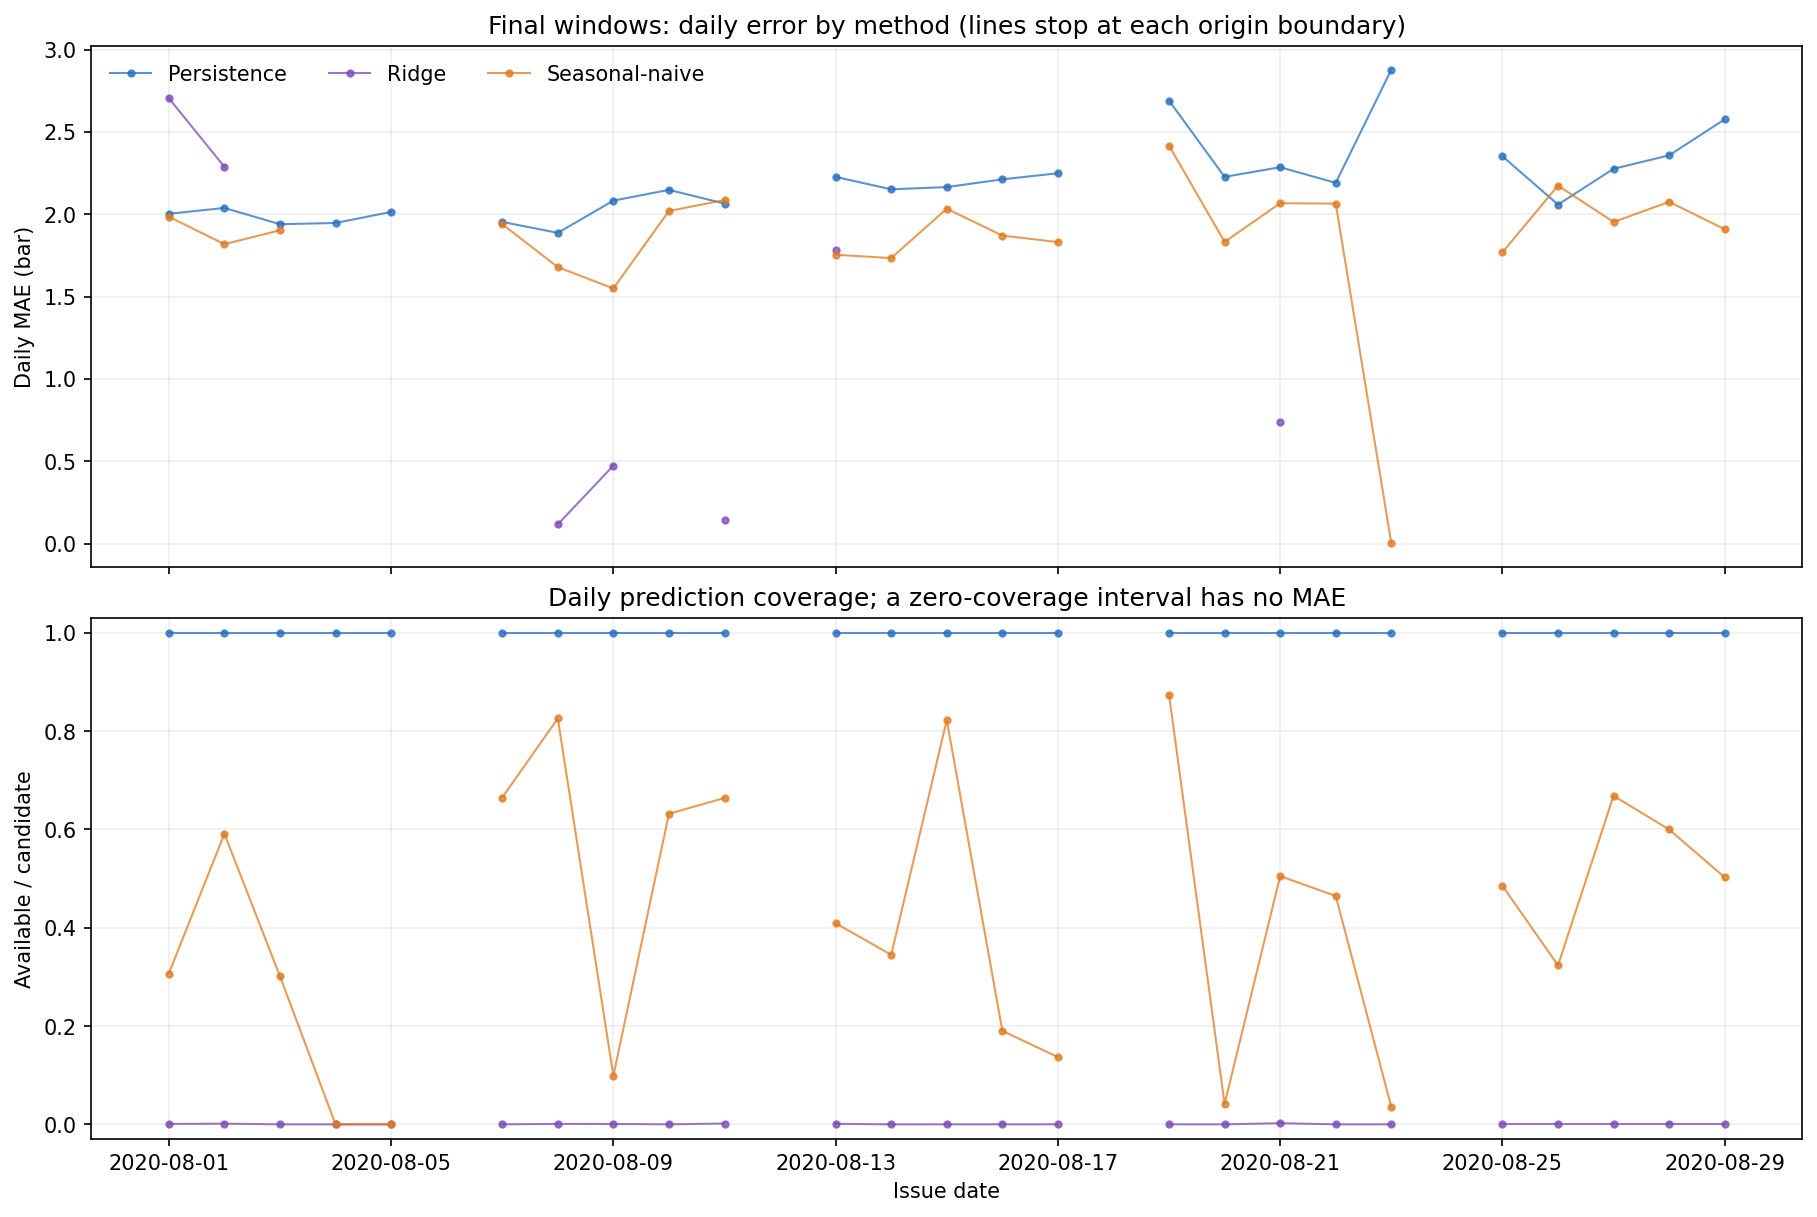

Displayed 87 origin-day-method summary rows; zero-coverage Ridge MAE is null by construction.


In [11]:
daily = pd.read_csv(project_path("results/analysis/error_coverage_by_day.csv"))
daily = daily[(daily.phase == "final") & daily.method.isin(["persistence","seasonal_naive","ridge"])].copy()
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True, constrained_layout=True)
colors = {"persistence":"#276FBF","seasonal_naive":"#E07A1F","ridge":"#7B4AB5"}
names = {"persistence":"Persistence","seasonal_naive":"Seasonal-naive","ridge":"Ridge"}
for method, group in daily.groupby("method"):
    for _, origin_group in group.groupby("origin_id"):
        x = pd.to_datetime(origin_group.issue_day)
        axes[0].plot(x, origin_group.mae, marker=".", linewidth=1, color=colors[method], alpha=.75,
                     label=names[method] if origin_group.origin_id.iloc[0] == group.origin_id.iloc[0] else None)
        axes[1].plot(x, origin_group.prediction_coverage, marker=".", linewidth=1, color=colors[method], alpha=.75)
axes[0].set_ylabel("Daily MAE (bar)"); axes[0].set_title("Final windows: daily error by method (lines stop at each origin boundary)")
axes[1].set_ylabel("Available / candidate"); axes[1].set_ylim(-.03,1.03); axes[1].set_xlabel("Issue date"); axes[1].set_title("Daily prediction coverage; a zero-coverage interval has no MAE")
axes[0].legend(ncol=3, frameon=False); axes[1].grid(alpha=.2); axes[0].grid(alpha=.2)
from io import BytesIO
daily_image = BytesIO(); fig.savefig(daily_image, format="png", dpi=150, bbox_inches="tight"); plt.close(fig)
show_png_with_alt(daily_image.getvalue(), "Daily MAE and prediction coverage for three methods, with lines separated by final origin.")
assert daily.loc[daily.method.eq("ridge") & daily.available_prediction_count.eq(0), "mae"].isna().all()
print(f"Displayed {len(daily):,} origin-day-method summary rows; zero-coverage Ridge MAE is null by construction.")

method,Persistence n,Ridge n,Seasonal n
Origin,,,
F1,28036,17,8121
F2,39519,21,22979
F3,36435,9,13743
F4,28560,17,13428
F5,36665,0,18894


,origin_id,method,scored_count,candidate_coverage,mae,rmse
15,F1,persistence,28036,100.000%,2.0003,4.3333
16,F1,ridge,17,0.059%,2.4597,3.6893
17,F1,seasonal_naive,8121,28.947%,1.8838,4.2075
18,F2,persistence,39519,100.000%,2.0273,4.3683
19,F2,ridge,21,0.062%,0.2331,0.4493
20,F2,seasonal_naive,22979,58.095%,1.9023,4.2239
21,F3,persistence,36435,100.000%,2.2032,4.5425
22,F3,ridge,9,0.024%,1.7841,2.9443
23,F3,seasonal_naive,13743,37.708%,1.8803,4.1836
24,F4,persistence,28560,100.000%,2.3919,4.7278


**Existing audited Phase 3 figure:** `results/analysis/figures/phase3_final_error_distributions.png`

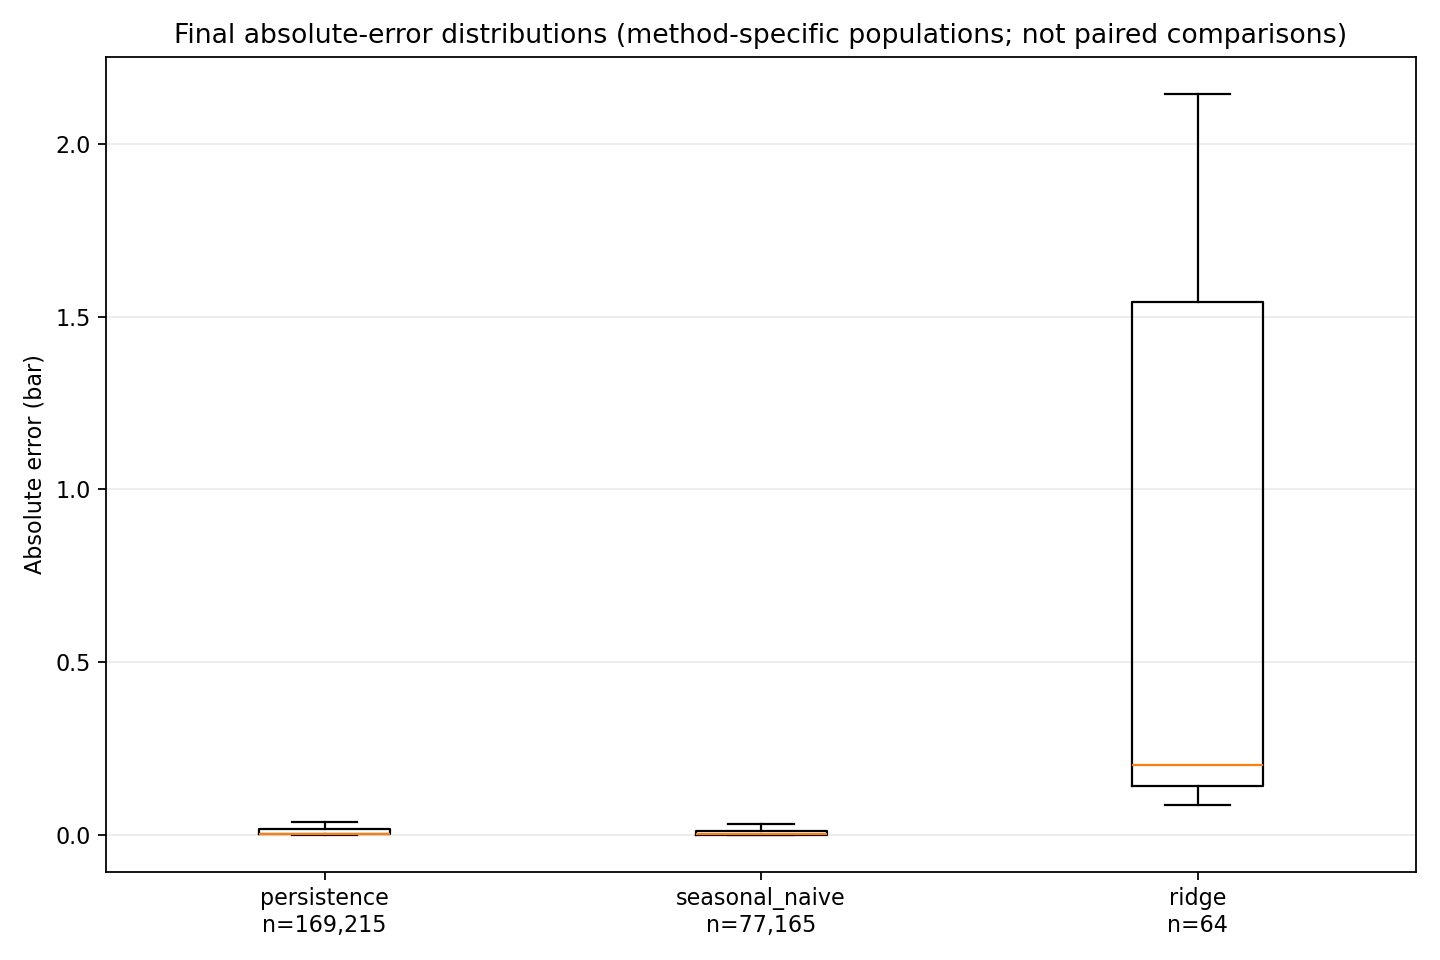

**Existing audited Phase 3 figure:** `results/analysis/figures/phase3_paired_baseline_error_difference.png`

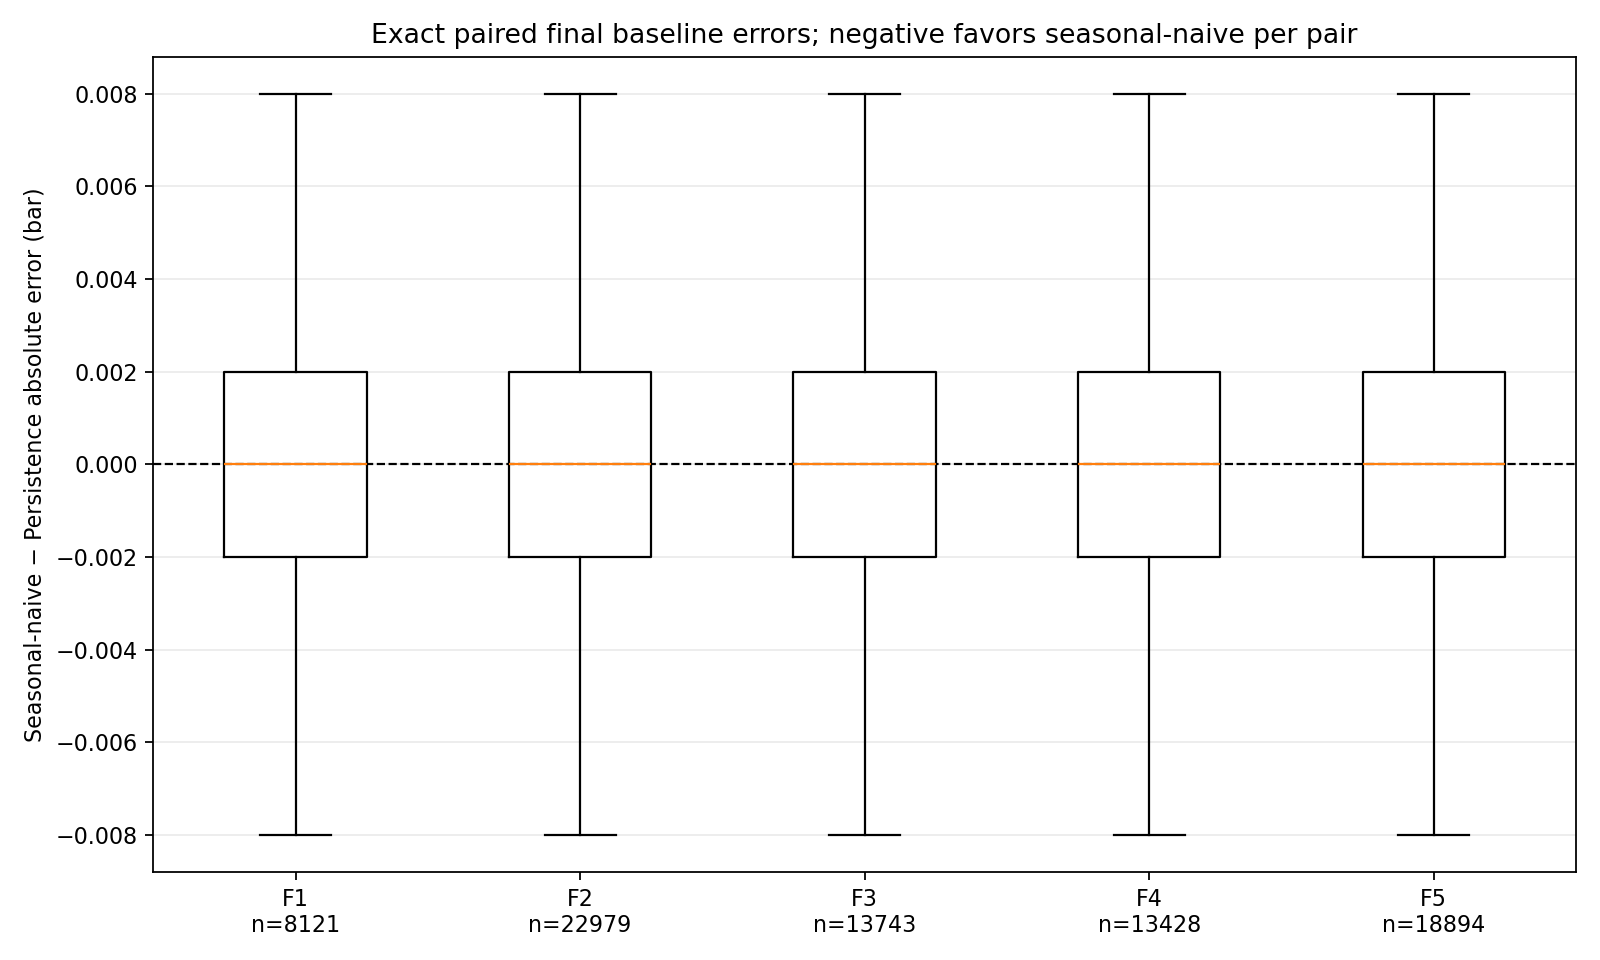

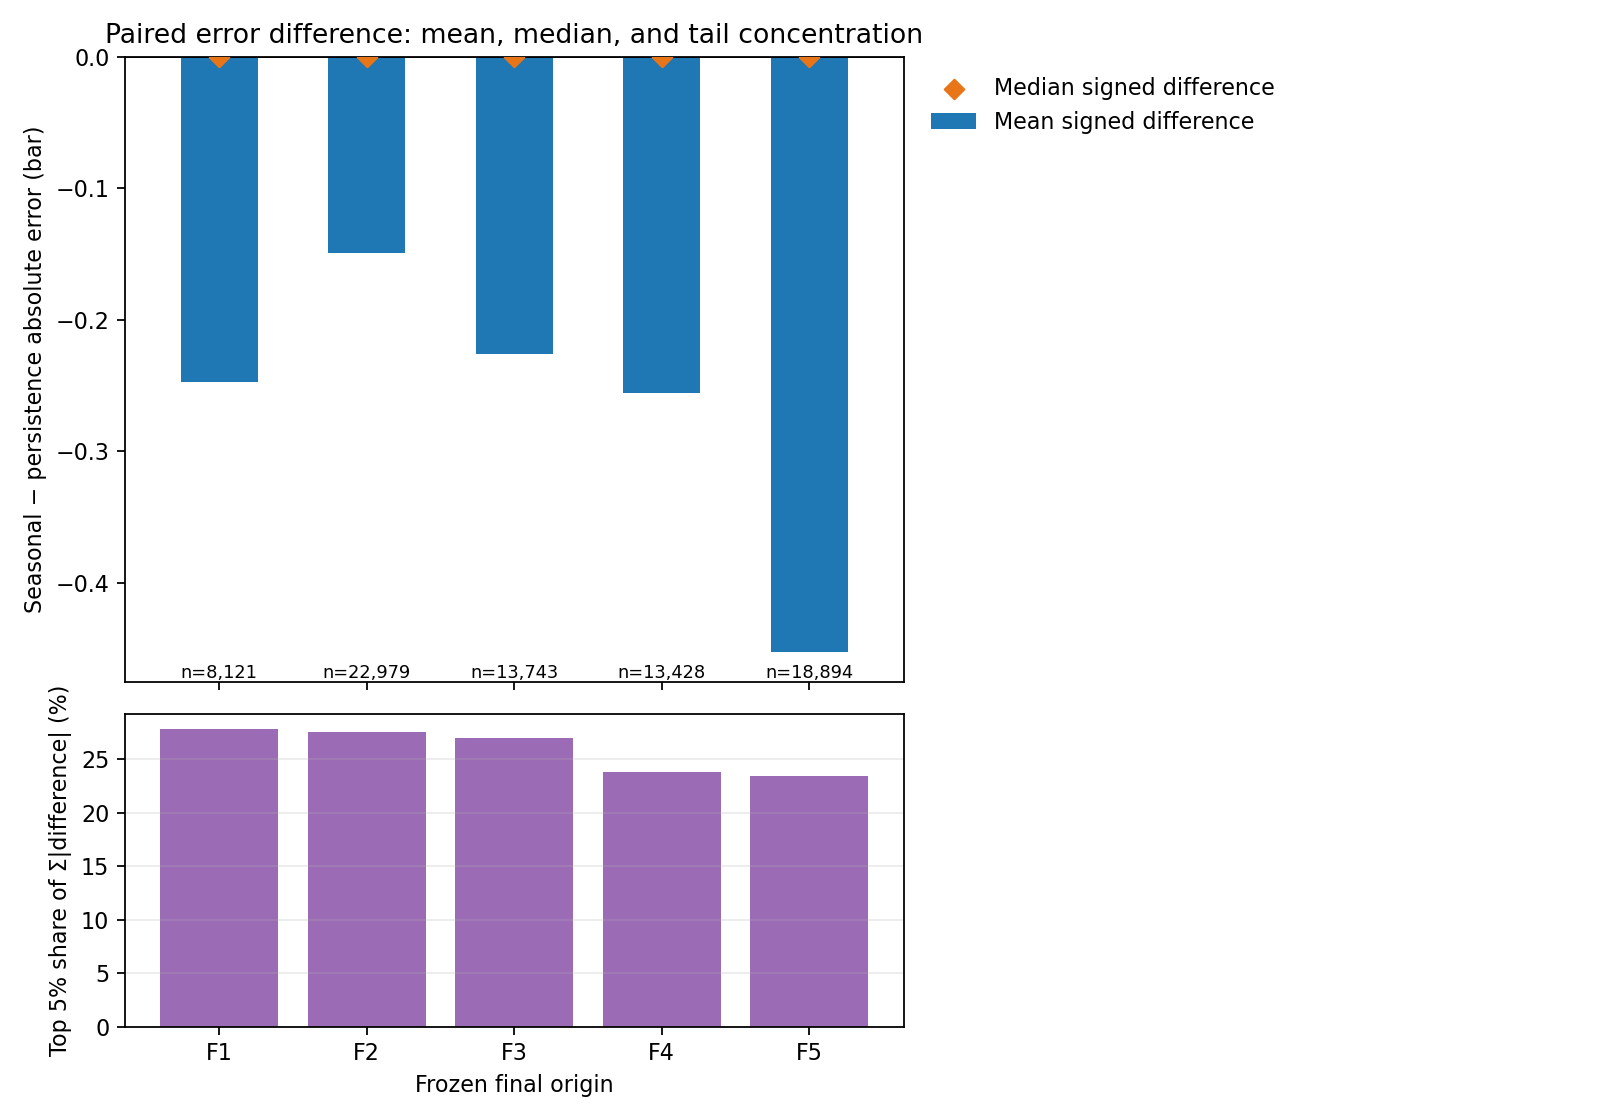

The lower panel is the top 5% share of total absolute paired difference; it is not a signed causal attribution.


In [12]:
# Per-origin error/coverage table with sample counts; values are from the audited summary.
display(origin_summary[origin_summary.phase.eq("final")].pivot(index="origin_id",columns="method",values="scored_count").rename_axis("Origin").rename(columns={"persistence":"Persistence n","seasonal_naive":"Seasonal n","ridge":"Ridge n"}))
display(origin_summary[origin_summary.phase.eq("final")][["origin_id","method","scored_count","candidate_coverage","mae","rmse"]].sort_values(["origin_id","method"]).style.format({"candidate_coverage":"{:.3%}","mae":"{:.4f}","rmse":"{:.4f}"},na_rep="—"))
for rel in ["results/analysis/figures/phase3_final_error_distributions.png", "results/analysis/figures/phase3_paired_baseline_error_difference.png"]:
    display(Markdown(f"**Existing audited Phase 3 figure:** `{rel}`"))
    caption = "Final per-method error distributions from the audited Phase 3 output." if "error_distributions" in rel else "Paired absolute-error differences on shared final Persistence and Seasonal-naive targets."
    show_png_with_alt(project_path(rel).read_bytes(), caption)
tail_figure = project_path("results/student_review_diagnostics/paired_error_tails.png").read_bytes()
show_png_with_alt(tail_figure, "Per-origin paired mean and median absolute-error differences, with top-five-percent absolute tail share.")
print("The lower panel is the top 5% share of total absolute paired difference; it is not a signed causal attribution.")

## 9. Drift and critical-period diagnosis

Monthly summaries show distribution shifts and changes in observed operating-state composition. June TP2 has median −0.012 bar and 75th percentile 7.348 bar; median motor current rises from 0.0425 A in May to 3.715 A in June, while `COMP=1` frequency changes from 81.7% to 71.9%. These are observed mixtures, not proof of sensor drift, faults, or a causal mechanism. The archive has 331 adjacent intervals over 60 seconds, with undocumented causes; September is observed only through 03:59:50 on September 1.

The UCI-reported **June 5–7, 2020** period is an applicability-boundary example: on 14,274 shared event-window targets, Persistence MAE is 0.6333 bar and Seasonal-naive MAE is 4.4586 bar. In the same D4 origin outside the reported window, the paired population has 44,691 targets and MAEs of 2.0455 and 1.9012 bar. The subgroup is retrospective and assigned by issue time. Report and sensor timestamps are naive, clock alignment is unverified, and UCI metadata contains inconsistent numbering/text. The contrast does not show that the reported fault caused the errors.

Across the five final origins, Seasonal-naive has lower paired MAE than Persistence on shared targets; the June window reverses this pattern, with Persistence lower. The reason is not established. Operating conditions, short-term pressure dynamics, or daily-pattern stability remain untested possibilities. UCI event-time alignment is uncertain.

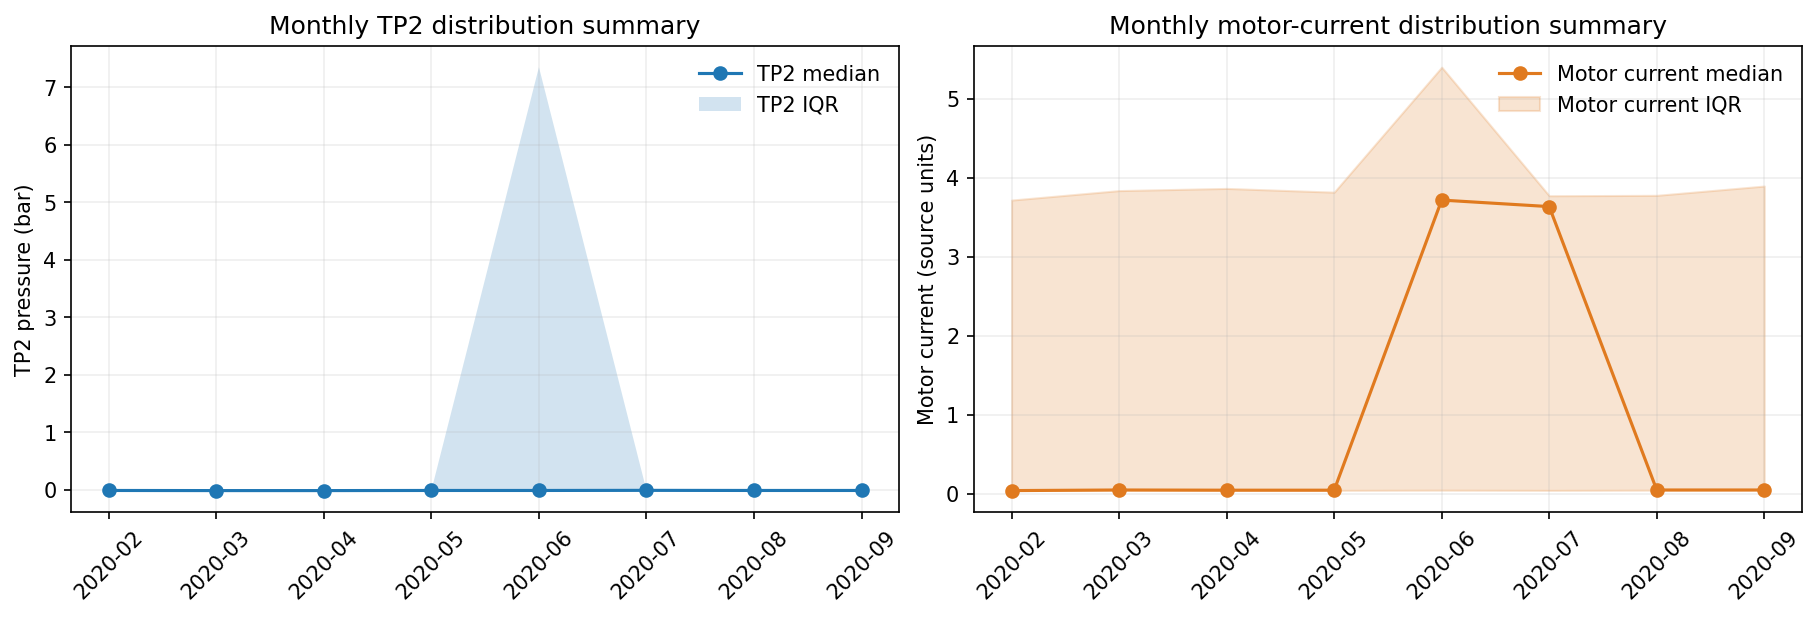

Month,Rows,COMP on fraction,COMP transitions/h,DV on fraction,DV transitions/h
2020-02,214850,0.939300,3.466000,0.060700,3.466000
2020-03,230448,0.827900,4.632400,0.172500,4.624300
2020-04,198734,0.838000,8.536000,0.175600,6.243300
2020-05,212800,0.816800,10.484500,0.171400,3.939700
2020-06,216514,0.718800,6.497900,0.259900,13.325200
2020-07,222638,0.844700,7.578000,0.158100,6.411300
2020-08,220434,0.873200,5.344100,0.126800,5.344100
2020-09,530,0.896200,2.076300,0.103800,2.076300


Month,Rows,Towers on fraction,Towers transitions/h
2020-02,214850,0.969700,4.649100
2020-03,230448,0.913700,11.051400
2020-04,198734,0.913300,13.635700
2020-05,212800,0.902300,16.531600
2020-06,216514,0.883000,22.566800
2020-07,222638,0.920100,11.871000
2020-08,220434,0.936500,8.507900
2020-09,530,0.950900,2.669500


Method,Candidates,Scored n,MAE (bar),RMSE (bar)
Persist,17315,17031,0.6369,0.9805
Seasonal,17315,14274,4.4586,5.8456
Ridge,17315,9,0.8394,0.9839
Paired baselines,14274,14274,0.6333,0.9711


Period summaries describe observed distribution changes; they do not establish causal or predictive drift.


D4 retrospective group,Paired n,Persistence MAE (bar),Seasonal-naive MAE (bar)
reported_event_issue_times,14274.000000,0.6333,4.4586
other_eligible_issue_times_same_origin,44691.000000,2.0455,1.9012


In [13]:
drift = pd.read_csv(project_path("results/analysis/drift_summary.csv"))
months = drift[drift.period_type.eq("calendar_month")].copy()
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
axes[0].plot(months.period_id, months.TP2_p50, marker="o", label="TP2 median")
axes[0].fill_between(range(len(months)), months.TP2_p25, months.TP2_p75, alpha=.2, label="TP2 IQR")
axes[0].set_ylabel("TP2 pressure (bar)"); axes[0].set_title("Monthly TP2 distribution summary")
axes[1].plot(months.period_id, months.Motor_current_p50, marker="o", color="#E07A1F", label="Motor current median")
axes[1].fill_between(range(len(months)), months.Motor_current_p25, months.Motor_current_p75, alpha=.2, color="#E07A1F", label="Motor current IQR")
axes[1].set_ylabel("Motor current (source units)"); axes[1].set_title("Monthly motor-current distribution summary")
for ax in axes:
    ax.set_xticks(range(len(months)), months.period_id, rotation=45); ax.grid(alpha=.2); ax.legend(frameon=False)
from io import BytesIO
drift_image = BytesIO(); fig.savefig(drift_image, format="png", dpi=150, bbox_inches="tight"); plt.close(fig)
show_png_with_alt(drift_image.getvalue(), "Monthly TP2 and motor-current medians and interquartile ranges.")
state_view = months[["period_id","row_count","COMP_value_1_rate","COMP_transitions_per_hour","DV_eletric_value_1_rate","DV_eletric_transitions_per_hour"]].copy()
state_view.columns = ["Month","Rows","COMP on fraction","COMP transitions/h","DV on fraction","DV transitions/h"]
tower_view = months[["period_id","row_count","Towers_value_1_rate","Towers_transitions_per_hour"]].copy()
tower_view.columns = ["Month","Rows","Towers on fraction","Towers transitions/h"]
display(state_view.round(4).style.hide(axis="index")); display(tower_view.round(4).style.hide(axis="index"))
critical = pd.read_csv(project_path("results/analysis/critical_period_summary.csv"))
critical_june = critical[critical.event_id.eq("UCI_failure_3") & critical.comparison_group.eq("reported_event_issue_times")][["method","candidate_issue_count","scored_count","mae","rmse"]].copy()
critical_june["method"] = critical_june["method"].map({"persistence":"Persist","seasonal_naive":"Seasonal","ridge":"Ridge","paired_baselines":"Paired baselines"})
critical_june.columns = ["Method","Candidates","Scored n","MAE (bar)","RMSE (bar)"]
display(critical_june.style.format({"MAE (bar)":"{:.4f}","RMSE (bar)":"{:.4f}"},na_rep="—").hide(axis="index"))
print("Period summaries describe observed distribution changes; they do not establish causal or predictive drift.")
context = critical[(critical.event_id.eq("UCI_failure_3")) & critical.method.eq("paired_baselines") & critical.comparison_group.isin(["reported_event_issue_times","other_eligible_issue_times_same_origin"])][["comparison_group","paired_count","paired_persistence_mae","paired_seasonal_mae"]].copy()
context.columns = ["D4 retrospective group","Paired n","Persistence MAE (bar)","Seasonal-naive MAE (bar)"]
display(context.style.format({"Persistence MAE (bar)":"{:.4f}","Seasonal-naive MAE (bar)":"{:.4f}"},na_rep="—").hide(axis="index"))

## 10. Ridge failure and availability diagnosis

Ridge requires all seven historical lag features at one issue time. The 300-second lag is the main observed bottleneck. In August, 220,249 of 220,434 TP2 300-second requests were more than five seconds older than requested; 185 were within tolerance, 60 failed the historical-gap rule, and 125 passed that lag’s rule. Only 94 August issues passed all seven feature rules. A ten-second median interval does not guarantee alignment at a requested time 300 seconds earlier. These archive lookup results do not establish physical clock drift.

Monthly issue-time eligibility differs from cumulative expanding-training rows, target-pair eligibility, and final scored coverage. The following tables report these populations separately; all D1–D5 and F1–F5 reconstructed training counts matched Phase 2B.

In [14]:
funnel = pd.read_csv(project_path("results/audit/phase2b_coverage_funnel.csv"))
ridge_funnel = funnel[(funnel.role.eq("training")) & funnel.origin_id.isin(["D1","D2","D3","D4","D5"])].copy()
lag_stages = ["TP2_lag_300s_available","TP3_lag_300s_available","Motor_current_lag_300s_available","all_feature_history_gaps_pass"]
lag_view = ridge_funnel[ridge_funnel.stage.isin(lag_stages)].pivot(index="origin_id",columns="stage",values="remaining_count").reindex(columns=lag_stages).fillna(0).astype(int)
lag_view.columns = ["TP2 lag 300s","TP3 lag 300s","Motor lag 300s","All feature histories"]
lag_view.index.name = "Origin"; lag_view = lag_view.reset_index()
display(lag_view.style.hide(axis="index"))
ridge_source = origin_summary[(origin_summary.phase.eq("final")) & origin_summary.method.eq("ridge")][["origin_id","candidate_issue_count","available_prediction_count","scored_count","candidate_coverage","mae","rmse"]].copy()
assert int(ridge_source.scored_count.sum()) == 64
assert int(ridge_source.loc[ridge_source.origin_id.eq("F5"),"available_prediction_count"].iloc[0]) == 0
ridge_rows = ridge_source.copy(); ridge_rows.columns = ["Origin","Candidates","Available","Scored n","Coverage","MAE (bar)","RMSE (bar)"]
display(ridge_rows.style.format({"Coverage":"{:.4%}","MAE (bar)":"{:.4f}","RMSE (bar)":"{:.4f}"},na_rep="—").hide(axis="index"))

Origin,TP2 lag 300s,TP3 lag 300s,Motor lag 300s,All feature histories
D1,0,0,0,0
D2,174,174,174,158
D3,10012,10012,10012,9986
D4,21597,21597,21597,21568
D5,42697,42697,42697,42650


Origin,Candidates,Available,Scored n,Coverage,MAE (bar),RMSE (bar)
F1,28576,17,17,0.0595%,2.4597,3.6893
F2,40143,25,21,0.0623%,0.2331,0.4493
F3,37069,9,9,0.0243%,1.7841,2.9443
F4,29165,17,17,0.0583%,0.7365,1.1007
F5,37251,0,0,0.0000%,—,—


In [15]:
posthoc_month = pd.read_csv(project_path("results/student_review_diagnostics/monthly_joint_feature_eligibility.csv"))
posthoc_lag = pd.read_csv(project_path("results/student_review_diagnostics/monthly_lag_alignment.csv"))
m = posthoc_month[posthoc_month.period_type.eq("month")].copy()
l = posthoc_lag[(posthoc_lag.period_type.eq("month")) & posthoc_lag.feature.eq("TP2")].pivot(index="period_id",columns="lag_seconds",values="final_lag_eligibility_count")
v = m.set_index("period_id")[["candidate_issue_count","joint_seven_feature_eligible_count"]].join(l)
v["Joint rate"] = v.joint_seven_feature_eligible_count / v.candidate_issue_count
v = v.rename(columns={"candidate_issue_count":"Candidate issue n","joint_seven_feature_eligible_count":"All 7 eligible n",10:"10s TP2 lag n",60:"60s TP2 lag n",300:"300s TP2 lag n"})
v.index.name = "Calendar month"
v = v.reset_index()
assert v["All 7 eligible n"].tolist() == [0,206,10011,12136,21204,4122,94]
assert v["Candidate issue n"].tolist() == [214850,230448,198734,212800,216514,222638,220434]
display(Markdown("**Monthly issue-time feature eligibility** — denominators are candidate issue observations within each month. Lag counts are per-feature lookups; the seven-feature count is their joint intersection."))
display(v.style.format({"Joint rate":"{:.3%}"}).hide(axis="index"))
w = posthoc_month[posthoc_month.period_type.eq("frozen_window")].set_index("period_id")[["candidate_issue_count","joint_seven_feature_eligible_count","joint_seven_feature_eligibility_rate"]]
w.columns = ["Window issue n","All 7 eligible n","All 7 rate"]
w.index.name = "Origin"
w = w.reset_index()
display(Markdown("**Frozen-window issue-time eligibility** — this is before requiring a valid future label and a saved Ridge forecast."))
display(w.style.format({"All 7 rate":"{:.3%}"}).hide(axis="index"))
t = pd.read_csv(project_path("results/student_review_diagnostics/expanding_training_reconciliation.csv"))
assert t.count_match.all()
t = t[["origin_id","target_and_gap_eligible_count","feature_eligible_training_count_reconstructed","saved_phase2b_training_sample_count"]]
t.columns = ["Origin","Target + gap eligible pairs","Reconstructed training rows","Saved Phase 2B training rows"]
display(Markdown("**Cumulative expanding-training eligibility** — issue `< origin`, actual matched label `<= origin`; these are not monthly samples. All counts match Phase 2B."))
display(t.style.format({c:"{:,.0f}" for c in t.columns if c != "Origin"}).hide(axis="index"))
a = posthoc_lag[(posthoc_lag.period_type.eq("month")) & posthoc_lag.period_id.eq("2020-08") & posthoc_lag.feature.eq("TP2") & posthoc_lag.lag_seconds.eq(300)].iloc[0]
assert (int(a.candidate_issue_count),int(a.stale_over_5s_count),int(a.acceptable_age_0_to_5_match_count),int(a.history_gap_rejection_count),int(a.final_lag_eligibility_count)) == (220434,220249,185,60,125)
assert int(m.loc[m.period_id.eq("2020-08"),"joint_seven_feature_eligible_count"].iloc[0]) == 94
print("August 300-second and all-seven counts match the Phase 5A diagnostic.")

**Monthly issue-time feature eligibility** — denominators are candidate issue observations within each month. Lag counts are per-feature lookups; the seven-feature count is their joint intersection.

Calendar month,Candidate issue n,All 7 eligible n,10s TP2 lag n,60s TP2 lag n,300s TP2 lag n,Joint rate
2020-02,214850,0,196034,102048,0,0.000%
2020-03,230448,206,210248,109427,234,0.089%
2020-04,198734,10011,182218,99008,10885,5.037%
2020-05,212800,12136,195208,107129,12456,5.703%
2020-06,216514,21204,199542,113078,22970,9.793%
2020-07,222638,4122,203476,107563,4493,1.851%
2020-08,220434,94,201098,104596,125,0.043%


**Frozen-window issue-time eligibility** — this is before requiring a valid future label and a saved Ridge forecast.

Origin,Window issue n,All 7 eligible n,All 7 rate
F1,28576,17,0.059%
F2,40143,25,0.062%
F3,37069,9,0.024%
F4,29165,17,0.058%
F5,37251,0,0.000%


**Cumulative expanding-training eligibility** — issue `< origin`, actual matched label `<= origin`; these are not monthly samples. All counts match Phase 2B.

Origin,Target + gap eligible pairs,Reconstructed training rows,Saved Phase 2B training rows
D1,"212,356",0,0
D2,"439,183",158,158
D3,"633,965","9,986","9,986"
D4,"842,555","21,568","21,568"
D5,"1,055,970","42,650","42,650"
F1,"1,273,871","46,711","46,711"
F2,"1,310,538","46,728","46,728"
F3,"1,358,562","46,749","46,749"
F4,"1,402,887","46,784","46,784"
F5,"1,440,152","46,801","46,801"


August 300-second and all-seven counts match the Phase 5A diagnostic.


## 11. Monitoring, retraining, and fallback

The monitoring proposal records input freshness, timestamp gaps, feature availability, forecast coverage, delayed-label scoring, and distribution changes. Any future retraining or fallback requires a separate evaluation. In this retrospective archive, missing predictions remain unavailable rather than being assigned zero error.

The existing offline Ridge-to-Persistence replay found 169,215 eligible final targets, invoked Persistence for 169,151 (about 99.962%), achieved 100% retrospective replay coverage, and had MAE/RMSE about 2.1852/4.5285 bar. This is a retrospective replay of saved predictions under the zero-additional-latency assumption. It is **not deployed, live-tested, or validated as a production fallback**.

In [16]:
fallback = json.loads(project_path("results/analysis/fallback_replay_summary.json").read_text())
assert fallback["status"] == "DESCRIPTIVE_OFFLINE_REPLAY_ONLY"
assert fallback["eligible_target_count"] == 169215 and fallback["fallback_trigger_count"] == 169151
assert np.isclose(fallback["fallback_trigger_fraction_of_valid_targets"], 0.9996217829388647)
display(pd.DataFrame([
    ("Eligible final targets", fallback["eligible_target_count"]),
    ("Persistence fallback triggers", fallback["fallback_trigger_count"]),
    ("Fallback share", f"{fallback['fallback_trigger_fraction_of_valid_targets']:.3%}"),
    ("Retrospective replay coverage", f"{fallback['prediction_coverage_after_replay']:.1%}"),
    ("Replay MAE / RMSE (bar)", f"{fallback['mae']:.4f} / {fallback['rmse']:.4f}"),
    ("Interpretation", "Retrospective replay only"),
], columns=["Replay summary","Verified value"]))

,Replay summary,Verified value
0,Eligible final targets,169215
1,Persistence fallback triggers,169151
2,Fallback share,99.962%
3,Retrospective replay coverage,100.0%
4,Replay MAE / RMSE (bar),2.1852 / 4.5285
5,Interpretation,Retrospective replay only


## 12. Limitations and conclusions

### What the observations show

- Across the five final windows, the baseline pair set contains 77,165 forecasts. The mean `|seasonal-naive error| − |persistence error|` is −0.2662 bar; the median is 0, IQR [−0.002, +0.002], and 5th/95th percentiles [−9.660, +9.442] bar. Typical differences are small, but both tails are substantial.
- TP2 has an uneven marginal distribution: monthly medians are near zero in February–August, while June’s 75th percentile is 7.348 bar. Marginal pressure is distinct from issue-to-target change and forecast error. Without an engineering loss threshold, an MAE near two bar cannot be labeled acceptable or unacceptable.
- Monthly motor-current and observed operating-state distributions also change. The summaries support period-to-period distribution shifts and possible regime dependence; they do not distinguish operating-mixture changes from sensor drift or identify a cause.
- Ridge produced 64 scored forecasts in the five final windows; the all-three-method population contains 27 targets. This sparse, selected evidence does not establish general forecasting performance.

### Scope limits

Timestamps are naive, no independent device-clock reference or historical publication times are available, and failure windows may not align exactly with sensor time. The June 5–7 subgroup is a retrospective applicability-boundary example, not a causal fault analysis. Forecasts overlap and are serially dependent. F2 shows that changing from 22,979 baseline pairs to 18 all-method common targets reverses Persistence/Seasonal-naive ordering; the small common subset cannot establish an overall ranking.

### Conclusion

Under the frozen retrospective rules, Seasonal-naive has lower paired MAE and RMSE than Persistence across the five final windows, but lower availability. Ridge coverage is too sparse for a broad comparison. The archive records event time and saved outcomes, not live historical availability or engineering acceptability. Interpretation remains limited to these observed populations and periods.

## Reproduction and AI-use disclosure

This notebook's standard run verifies the existing source and output artifacts and recreates review tables/figures without fitting models. Full result regeneration follows the repository README commands and requires excluded original data and locally regenerated large prediction CSVs. Runtime environment: `nussem1`, Python 3.10.18, pandas 2.3.1, NumPy 2.2.6, scikit-learn 1.7.1, matplotlib 3.10.5 (notebook verification also uses `nbformat`/`nbclient`).

AI assistance is disclosed in [`docs/ai_use_log.md`](../docs/ai_use_log.md). The student’s review and approval status are recorded in [`docs/student_independent_review.md`](../docs/student_independent_review.md) and [`docs/phase5b_student_revision_report.md`](../docs/phase5b_student_revision_report.md); approval remains pending.